# Tamaño de la capa latente en autoencoders para la detección de intrusos en red Replicación de Song et al. (2021) — NSL-KDD, IoTID20, N-BaIoT

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score,
    matthews_corrcoef,
    f1_score,
    accuracy_score,
    recall_score,
    confusion_matrix,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("data")
NSLKDD_DIR = DATA_DIR / "nslkdd"
IOTID20_DIR = DATA_DIR / "iotid20"
NBAIOT_DIR = DATA_DIR / "nbaiot"

I0000 00:00:1792013378.615849 1229068 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792013378.659242 1229068 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792013379.723989 1229068 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Leemos los datos y convertimos a dataframes

In [2]:
# Los .txt no traen encabezado: tomamos los nombres de las 41 features del encabezado del .arff
feature_cols = []
with open(NSLKDD_DIR / "KDDTrain+.arff") as f:
    for line in f:
        line = line.strip()
        if line.lower().startswith("@attribute"):
            # "@attribute 'duration' real" -> "duration"
            feature_cols.append(line.split()[1].strip("'"))
        elif line.lower().startswith("@data"):
            break

# En el .arff la última columna es 'class' (normal/anomaly); el .txt trae en su lugar
# el nombre específico del ataque y el nivel de dificultad
NSLKDD_COLS = feature_cols[:-1] + ["label", "difficulty"]
print(len(NSLKDD_COLS))
NSLKDD_COLS

43


['duration',
 'protocol_type',
 'service',
 'flag',
 'src_bytes',
 'dst_bytes',
 'land',
 'wrong_fragment',
 'urgent',
 'hot',
 'num_failed_logins',
 'logged_in',
 'num_compromised',
 'root_shell',
 'su_attempted',
 'num_root',
 'num_file_creations',
 'num_shells',
 'num_access_files',
 'num_outbound_cmds',
 'is_host_login',
 'is_guest_login',
 'count',
 'srv_count',
 'serror_rate',
 'srv_serror_rate',
 'rerror_rate',
 'srv_rerror_rate',
 'same_srv_rate',
 'diff_srv_rate',
 'srv_diff_host_rate',
 'dst_host_count',
 'dst_host_srv_count',
 'dst_host_same_srv_rate',
 'dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate',
 'dst_host_srv_diff_host_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_rerror_rate',
 'dst_host_srv_rerror_rate',
 'label',
 'difficulty']

In [3]:
# Los .txt son CSV (separados por comas) aunque tengan otra extensión
NSLKDD_data = pd.read_csv(NSLKDD_DIR / "KDDTrain+.txt", header=None, names=NSLKDD_COLS)
NSLKDD_test = pd.read_csv(NSLKDD_DIR / "KDDTest+.txt", header=None, names=NSLKDD_COLS)

print("Train:", NSLKDD_data.shape)
print("Test: ", NSLKDD_test.shape)
NSLKDD_data.head()

Train: (125973, 43)
Test:  (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


Definimos validation

In [4]:
NSLKDD_data["label"].unique()

<StringArray>
[         'normal',         'neptune',     'warezclient',         'ipsweep',
       'portsweep',        'teardrop',            'nmap',           'satan',
           'smurf',             'pod',            'back',    'guess_passwd',
       'ftp_write',        'multihop',         'rootkit', 'buffer_overflow',
            'imap',     'warezmaster',             'phf',            'land',
      'loadmodule',             'spy',            'perl']
Length: 23, dtype: str

In [5]:
NSLKDD_data["attack"] = (NSLKDD_data["label"] != "normal").astype(int)
NSLKDD_test["attack"] = (NSLKDD_test["label"] != "normal").astype(int)
NSLKDD_train, NSLKDD_validation = train_test_split(NSLKDD_data, test_size=.2, random_state=SEED, stratify=NSLKDD_data["label"])

## EDA — NSL-KDD
Según la documentación del dataset (Tavallaee et al., 2009), cada registro resume **una conexión de red** con 41 features en cuatro grupos:

| Grupo | Features | Qué describe |
|---|---|---|
| Básicas | 1–9 | Datos de la conexión TCP: duración, protocolo, servicio, flag de estado, bytes enviados/recibidos |
| Contenido | 10–22 | Indicadores dentro del payload: logins fallidos, accesos root, archivos creados, etc. (útiles para R2L/U2R) |
| Tráfico (tiempo) | 23–31 | Estadísticas de las conexiones al mismo host/servicio en los **últimos 2 segundos** (útiles para DoS) |
| Tráfico (host) | 32–41 | Las mismas estadísticas sobre las **últimas 100 conexiones** al host destino (útiles para Probe lentos) |

Los ataques se agrupan en cuatro categorías: **DoS** (negación de servicio), **Probe** (escaneo), **R2L** (acceso remoto no autorizado) y **U2R** (escalamiento a root). `KDDTest+` incluye 17 tipos de ataque que no están en train.

Todo el EDA se hace sobre `NSLKDD_train`. Validación y test no se exploran.

In [6]:
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid", context="notebook")

# Colores fijos por entidad (se usan igual en todo el EDA)
CLASS_PALETTE = {"Normal": "#2a78d6", "Ataque": "#eb6834"}
CATEGORY_ORDER = ["DoS", "Probe", "R2L", "U2R"]
CATEGORY_PALETTE = {"DoS": "#eb6834", "Probe": "#1baf7a", "R2L": "#eda100", "U2R": "#e87ba4"}

# Categorías de ataque según la documentación de KDD'99 / NSL-KDD.
# Incluye los ataques que solo aparecen en KDDTest+ para reutilizar el mapeo más adelante.
ATTACK_CATEGORY = {
    # DoS: saturan recursos para negar el servicio
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "apache2": "DoS", "mailbomb": "DoS", "processtable": "DoS",
    "udpstorm": "DoS",
    # Probe: escaneo y reconocimiento de la red
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe",
    "mscan": "Probe", "saint": "Probe",
    # R2L: acceso no autorizado desde una máquina remota
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L",
    "phf": "R2L", "spy": "R2L", "warezclient": "R2L", "warezmaster": "R2L",
    "named": "R2L", "sendmail": "R2L", "snmpgetattack": "R2L", "snmpguess": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "worm": "R2L",
    # U2R: escalamiento de privilegios de usuario a root
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R",
    "httptunnel": "U2R", "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
}

# Grupos de features según la documentación (Tavallaee et al., 2009)
FEATURE_GROUPS = {
    "Básicas (conexión TCP)": NSLKDD_COLS[0:9],
    "Contenido (payload)": NSLKDD_COLS[9:22],
    "Tráfico: ventana de 2 s": NSLKDD_COLS[22:31],
    "Tráfico: últimas 100 conexiones al host": NSLKDD_COLS[31:41],
}
CAT_COLS = ["protocol_type", "service", "flag"]

# El EDA se hace SOLO sobre el split de entrenamiento
eda = NSLKDD_train.copy()
eda["clase"] = eda["attack"].map({0: "Normal", 1: "Ataque"})
eda["categoria"] = eda["label"].map(ATTACK_CATEGORY).fillna("Normal")

print("Etiquetas sin categoría asignada:", set(eda.loc[eda["categoria"] == "Normal", "label"]) - {"normal"})
for grupo, cols in FEATURE_GROUPS.items():
    print(f"{grupo} ({len(cols)}): {', '.join(cols)}")

Etiquetas sin categoría asignada: set()
Básicas (conexión TCP) (9): duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent
Contenido (payload) (13): hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login
Tráfico: ventana de 2 s (9): count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate
Tráfico: últimas 100 conexiones al host (10): dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate


### Calidad de los datos
Tipos, valores faltantes, duplicados y features casi constantes.

In [7]:
print("Filas x columnas:", eda.shape)
print("Valores faltantes:", eda.isna().sum().sum())
print("Filas duplicadas (sin difficulty):", eda.drop(columns=["difficulty"]).duplicated().sum())

features = NSLKDD_COLS[:41]
resumen = pd.DataFrame({
    "tipo": eda[features].dtypes.astype(str),
    "n_unicos": eda[features].nunique(),
    "pct_ceros": (eda[features] == 0).mean().mul(100).round(2),
})
# Features donde >99 % de los valores son 0: aportan muy poca información
resumen.sort_values("pct_ceros", ascending=False).head(15)

Filas x columnas: (100778, 46)
Valores faltantes: 0
Filas duplicadas (sin difficulty): 0


,tipo,n_unicos,pct_ceros
num_outbound_cmds,int64,1,100.00
is_host_login,int64,2,100.00
urgent,int64,4,99.99
land,int64,2,99.98
num_shells,int64,3,99.96
su_attempted,int64,3,99.94
num_failed_logins,int64,6,99.91
root_shell,int64,2,99.87
num_file_creations,int64,32,99.77
num_access_files,int64,10,99.71


### Variable objetivo
Balance normal vs. ataque y distribución por categoría de ataque.

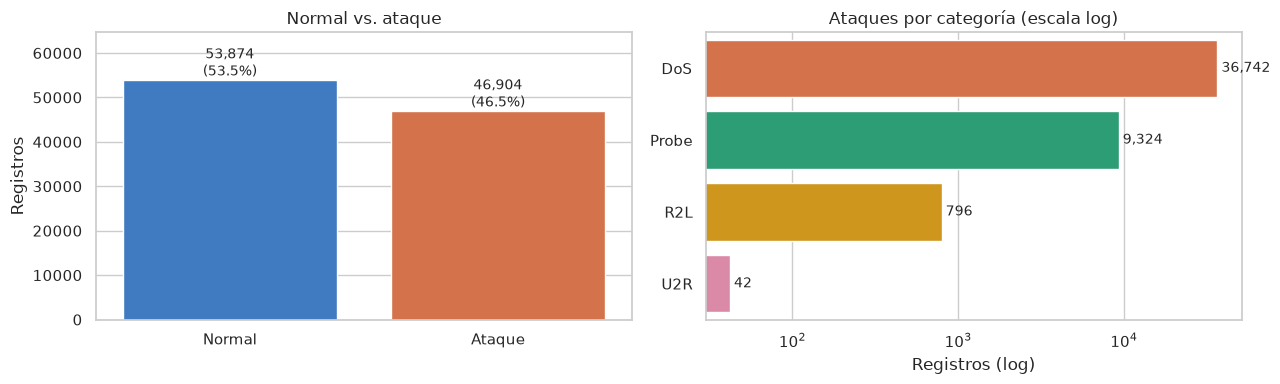

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=eda, x="clase", hue="clase", palette=CLASS_PALETTE,
              order=["Normal", "Ataque"], legend=False, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}\n({p.get_height() / len(eda):.1%})",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=10)
axes[0].set(title="Normal vs. ataque", xlabel="", ylabel="Registros")
axes[0].margins(y=0.2)

ataques = eda[eda["attack"] == 1]
sns.countplot(data=ataques, y="categoria", hue="categoria", order=CATEGORY_ORDER,
              palette=CATEGORY_PALETTE, legend=False, ax=axes[1])
axes[1].set_xscale("log")
for p in axes[1].patches:
    axes[1].annotate(f" {p.get_width():,.0f}", (p.get_width(), p.get_y() + p.get_height() / 2),
                     va="center", fontsize=10)
axes[1].set(title="Ataques por categoría (escala log)", xlabel="Registros (log)", ylabel="")
plt.tight_layout()
plt.show()

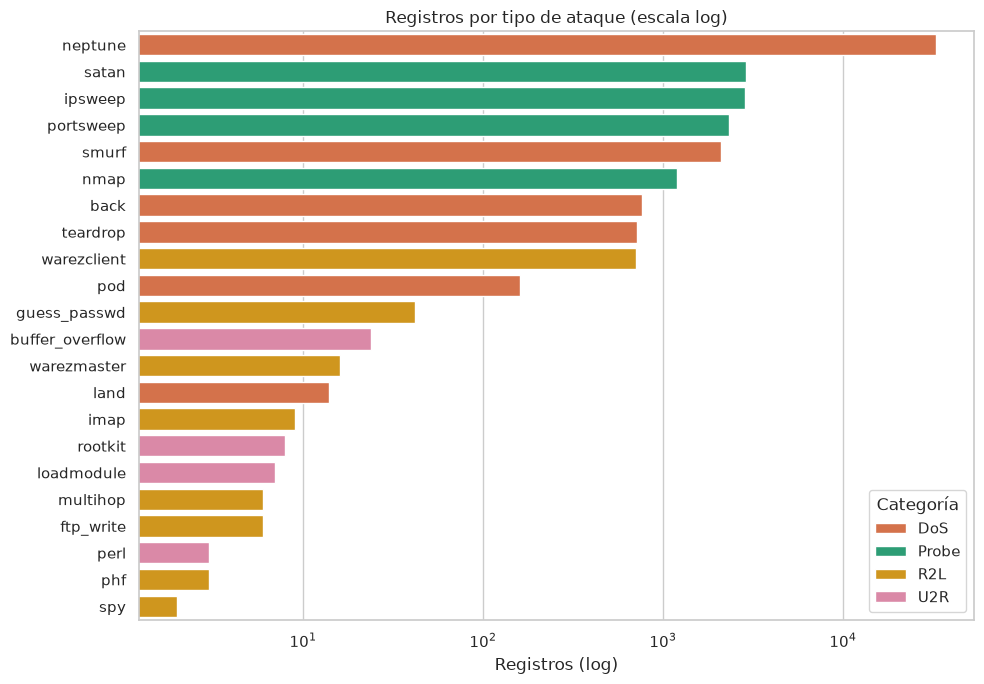

In [9]:
orden_labels = ataques["label"].value_counts().index
fig, ax = plt.subplots(figsize=(10, 7))
sns.countplot(data=ataques, y="label", hue="categoria", order=orden_labels,
              hue_order=CATEGORY_ORDER, palette=CATEGORY_PALETTE, dodge=False, ax=ax)
ax.set_xscale("log")
ax.set(title="Registros por tipo de ataque (escala log)", xlabel="Registros (log)", ylabel="")
ax.legend(title="Categoría", loc="lower right")
plt.tight_layout()
plt.show()

### Features categóricas
`protocol_type`, `flag` y `logged_in` (binaria), y los servicios más frecuentes.

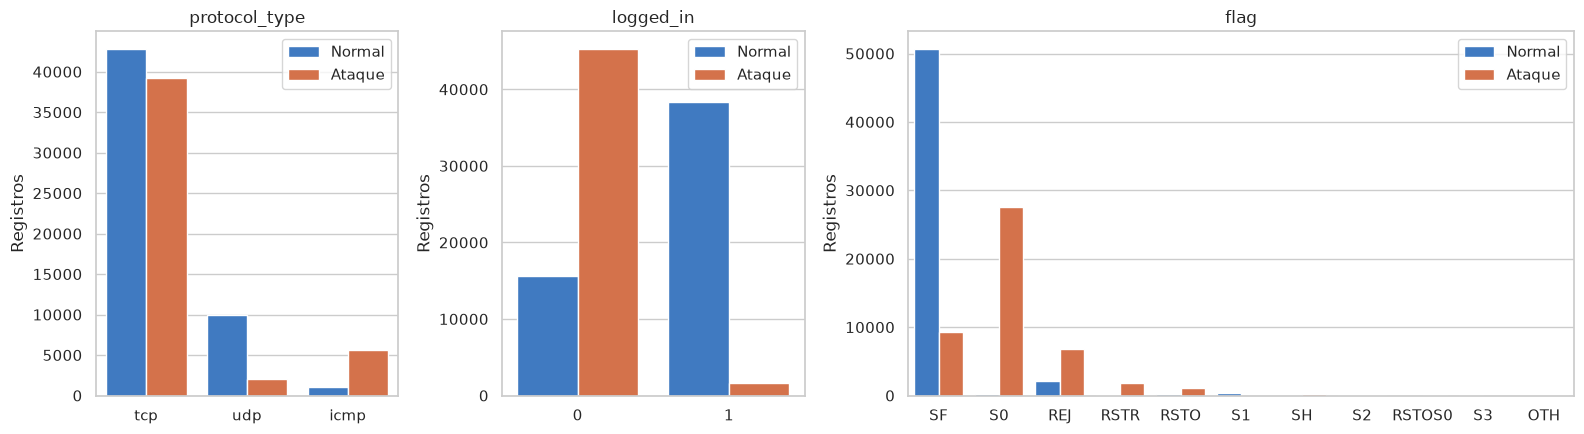

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 2.2]})
for ax, col in zip(axes, ["protocol_type", "logged_in", "flag"]):
    orden = eda[col].value_counts().index
    sns.countplot(data=eda, x=col, hue="clase", order=orden, hue_order=["Normal", "Ataque"],
                  palette=CLASS_PALETTE, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Registros")
    ax.legend(title="")
plt.tight_layout()
plt.show()

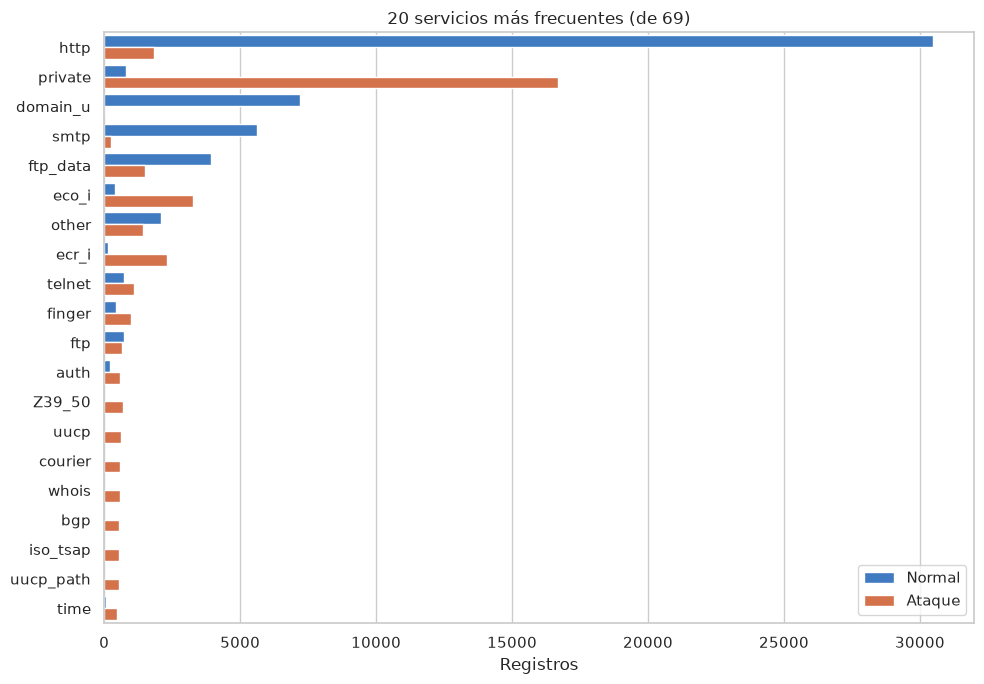

In [11]:
top_servicios = eda["service"].value_counts().head(20).index
fig, ax = plt.subplots(figsize=(10, 7))
sns.countplot(data=eda[eda["service"].isin(top_servicios)], y="service", hue="clase",
              order=top_servicios, hue_order=["Normal", "Ataque"], palette=CLASS_PALETTE, ax=ax)
ax.set(title=f"20 servicios más frecuentes (de {eda['service'].nunique()})",
       xlabel="Registros", ylabel="")
ax.legend(title="")
plt.tight_layout()
plt.show()

### Features numéricas muy sesgadas
`duration`, `src_bytes` y `dst_bytes` abarcan varios órdenes de magnitud, así que se grafican con `log1p`.

              count          mean           std  min  25%   50%    75%  \
duration   100778.0    285.998551  2.587735e+03  0.0  0.0   0.0    0.0   
src_bytes  100778.0  52348.686747  6.526922e+06  0.0  0.0  44.0  276.0   
dst_bytes  100778.0  20077.631785  4.315373e+06  0.0  0.0   0.0  522.0   

                    max  
duration   4.290800e+04  
src_bytes  1.379964e+09  
dst_bytes  1.309937e+09  


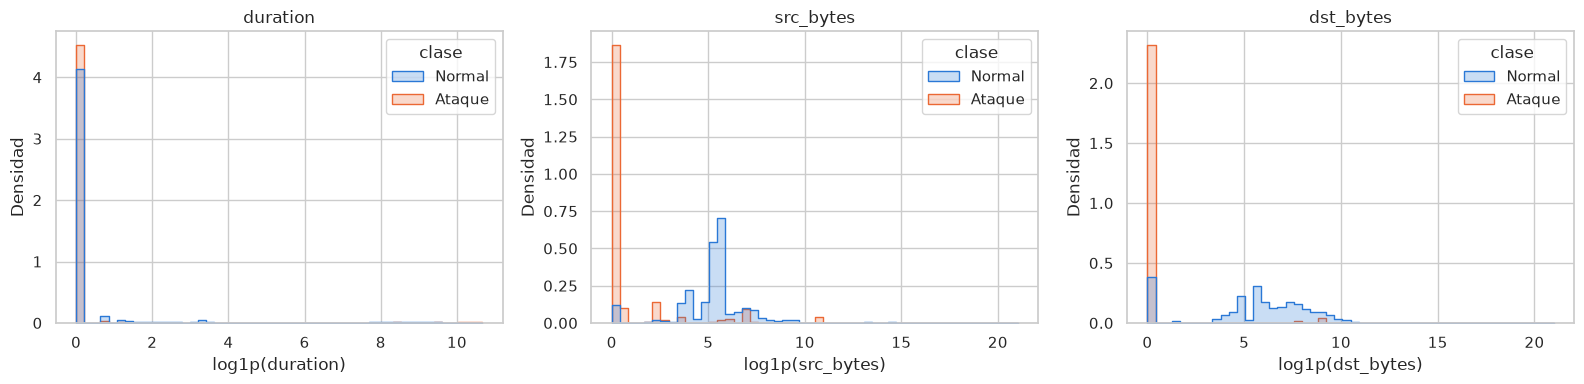

In [12]:
print(eda[["duration", "src_bytes", "dst_bytes"]].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["duration", "src_bytes", "dst_bytes"]):
    sns.histplot(data=eda, x=np.log1p(eda[col]), hue="clase", hue_order=["Normal", "Ataque"],
                 palette=CLASS_PALETTE, stat="density", common_norm=False,
                 element="step", bins=50, ax=ax)
    ax.set(title=col, xlabel=f"log1p({col})", ylabel="Densidad")
plt.tight_layout()
plt.show()

### ¿Qué features separan mejor las clases?
Información mutua (MI) entre cada feature y la etiqueta binaria, calculada sobre una muestra de 20 000 filas para que no tarde demasiado. La MI detecta relaciones no lineales, a diferencia de la correlación.

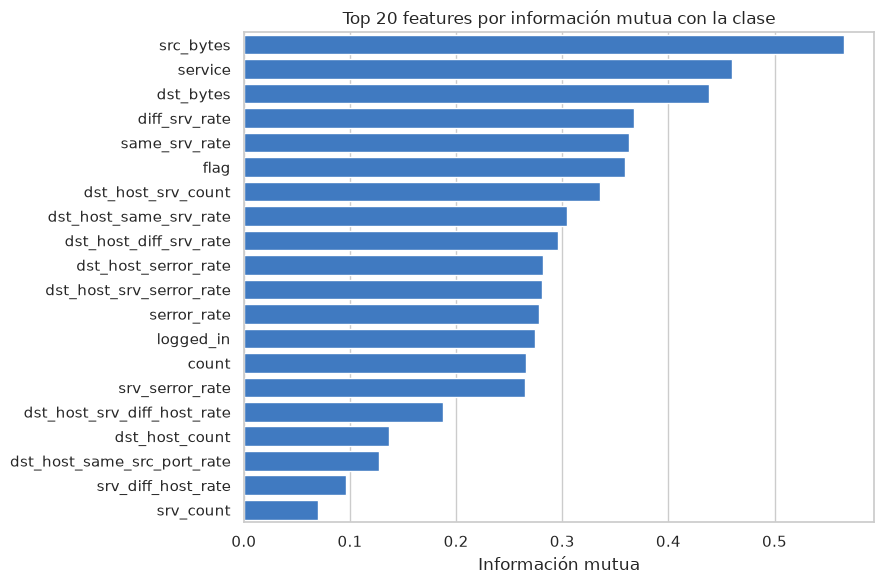

In [13]:
X_mi = eda[features].copy()
for col in CAT_COLS:
    X_mi[col] = X_mi[col].astype("category").cat.codes
muestra = X_mi.sample(20_000, random_state=SEED)

mi = mutual_info_classif(muestra, eda.loc[muestra.index, "attack"],
                         discrete_features=[c in CAT_COLS for c in features],
                         random_state=SEED)
mi = pd.Series(mi, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=mi.head(20).values, y=mi.head(20).index, color=CLASS_PALETTE["Normal"], ax=ax)
ax.set(title="Top 20 features por información mutua con la clase", xlabel="Información mutua", ylabel="")
plt.tight_layout()
plt.show()

# Preprocesamiento


In [14]:
# Features: las 41 columnas originales. label, difficulty y attack quedan fuera (fuga de información)
FEATURES = NSLKDD_COLS[:41]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

X_train, y_train = NSLKDD_train[FEATURES], NSLKDD_train["attack"]
X_val, y_val = NSLKDD_validation[FEATURES], NSLKDD_validation["attack"]
X_test, y_test = NSLKDD_test[FEATURES], NSLKDD_test["attack"]

print(f"Categóricas: {len(CAT_COLS)} | Numéricas: {len(NUM_COLS)}")
for nombre, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{nombre:>5}: X {X.shape} | % ataques = {y.mean():.3f}")

Categóricas: 3 | Numéricas: 38
train: X (100778, 41) | % ataques = 0.465
  val: X (25195, 41) | % ataques = 0.465
 test: X (22544, 41) | % ataques = 0.569


In [15]:
from sklearn.compose import ColumnTransformer

preprocesador = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ("num", StandardScaler(), NUM_COLS),
])

# fit SOLO con train; validación y test solo se transforman
X_train_prep = preprocesador.fit_transform(X_train)
X_val_prep = preprocesador.transform(X_val)
X_test_prep = preprocesador.transform(X_test)
FEATURE_NAMES = preprocesador.get_feature_names_out()

print("Train:", X_train_prep.shape)
print("Val:  ", X_val_prep.shape)
print("Test: ", X_test_prep.shape)

# Categorías de test que no se vieron en train (quedan como un vector de ceros)
for col in CAT_COLS:
    nuevas = set(X_test[col]) - set(X_train[col])
    print(f"{col}: categorías nuevas en test -> {nuevas or 'ninguna'}")

Train: (100778, 121)
Val:   (25195, 121)
Test:  (22544, 121)
protocol_type: categorías nuevas en test -> ninguna
service: categorías nuevas en test -> ninguna


flag: categorías nuevas en test -> ninguna


## Baseline: XGBoost

In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=1000,          # tope alto; el early stopping decide dónde parar
    learning_rate=0.05,
    max_depth=6,
    early_stopping_rounds=10,   # se detiene si el logloss de validación no mejora en 10 rondas
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
)
# Se evalúa en train y validación para graficar ambas curvas.
# El early stopping usa el ÚLTIMO conjunto de eval_set, por eso validación va al final.
xgb_model.fit(
    X_train_prep, y_train,
    eval_set=[(X_train_prep, y_train), (X_val_prep, y_val)],
    verbose=100,
)

print("Mejor iteración:", xgb_model.best_iteration)
print("Mejor logloss en validación:", round(xgb_model.best_score, 5))

[0]	validation_0-logloss:0.64318	validation_1-logloss:0.64328


[100]	validation_0-logloss:0.00879	validation_1-logloss:0.01005


[200]	validation_0-logloss:0.00301	validation_1-logloss:0.00451


[300]	validation_0-logloss:0.00177	validation_1-logloss:0.00337


[400]	validation_0-logloss:0.00109	validation_1-logloss:0.00285


[417]	validation_0-logloss:0.00103	validation_1-logloss:0.00284


Mejor iteración: 407
Mejor logloss en validación: 0.00284


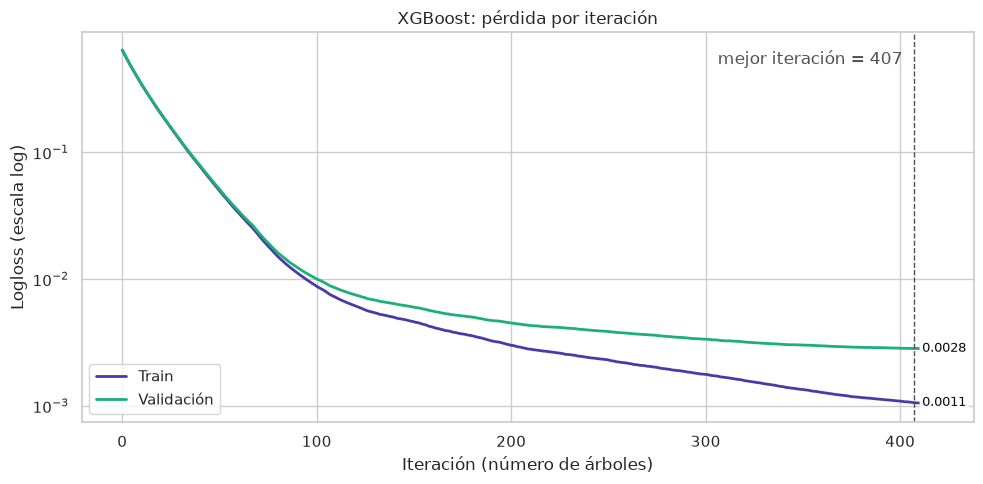

In [17]:
# Curvas de aprendizaje: logloss por iteración en train y validación
historial = xgb_model.evals_result()
curvas = pd.DataFrame({
    "Train": historial["validation_0"]["logloss"],
    "Validación": historial["validation_1"]["logloss"],
})
curvas.index.name = "iteracion"
curvas_long = curvas.reset_index().melt(id_vars="iteracion", var_name="conjunto", value_name="logloss")

LOSS_PALETTE = {"Train": "#4a3aa7", "Validación": "#1baf7a"}
mejor = xgb_model.best_iteration

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=curvas_long, x="iteracion", y="logloss", hue="conjunto",
             palette=LOSS_PALETTE, linewidth=2, ax=ax)
ax.axvline(mejor, color="#52514e", linestyle="--", linewidth=1)
ax.annotate(f"mejor iteración = {mejor}", (mejor, curvas["Validación"].max()),
            xytext=(-8, 0), textcoords="offset points", ha="right", va="top", color="#52514e")
# Valor final de cada curva junto a la línea
for conjunto, valor in curvas.iloc[mejor].items():
    ax.annotate(f"{valor:.4f}", (mejor, valor), xytext=(6, 0), textcoords="offset points",
                va="center", color="#0b0b0b", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"))
ax.set_yscale("log")  # la pérdida cae varios órdenes de magnitud
ax.set(title="XGBoost: pérdida por iteración", xlabel="Iteración (número de árboles)",
       ylabel="Logloss (escala log)")
ax.legend(title="")
plt.tight_layout()
plt.show()

### Evaluación en test
Se usan las métricas del artículo (Song et al., 2021) con **ataque = clase positiva**: accuracy, TPR (tasa de detección), FPR (falsas alarmas), F1 y MCC (métrica principal, robusta al desbalance). Se agrega el AUC, que no depende del umbral.

La misma función `calcular_metricas` se reutiliza después con el autoencoder, para que la comparación sea directa.

In [18]:
def calcular_metricas(y_real, y_pred, score=None):
    """Métricas de Song et al. (2021). y_pred binario (1 = ataque); score opcional para el AUC."""
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    metricas = {
        "accuracy": accuracy_score(y_real, y_pred),
        "tpr": tp / (tp + fn),   # de los ataques reales, cuántos se detectan
        "fpr": fp / (fp + tn),   # de los normales reales, cuántos se marcan como ataque
        "f1": f1_score(y_real, y_pred),
        "mcc": matthews_corrcoef(y_real, y_pred),
    }
    if score is not None:
        metricas["auc"] = roc_auc_score(y_real, score)
    return metricas

In [19]:
# XGBoost es supervisado: umbral estándar de 0.5 sobre la probabilidad de ataque
UMBRAL_XGB = 0.5
conjuntos = {"validación": (X_val_prep, y_val), "test": (X_test_prep, y_test)}

filas = []
for conjunto, (X, y) in conjuntos.items():
    score = xgb_model.predict_proba(X)[:, 1]
    pred = (score >= UMBRAL_XGB).astype(int)
    filas.append({"modelo": "XGBoost", "dataset": "NSL-KDD", "conjunto": conjunto,
                  **calcular_metricas(y, pred, score)})

baseline_xgb = pd.DataFrame(filas)
baseline_xgb.round(4)

,modelo,dataset,conjunto,accuracy,tpr,fpr,f1,mcc,auc
0,XGBoost,NSL-KDD,validación,0.9991,0.9987,0.0005,0.9991,0.9982,1.0000
1,XGBoost,NSL-KDD,test,0.7907,0.6542,0.0289,0.7806,0.6363,0.9672


### Desempeño por categoría de ataque en test
El artículo reporta la TPR por categoría (DoS, Probe, R2L, U2R). Para la fila *Normal* la tasa mostrada es la FPR.

Además se separan los ataques **vistos** en entrenamiento de los que **solo aparecen en test**: es la forma de medir cuánto pierde un modelo supervisado frente a ataques nuevos, que es justamente la ventaja que se le atribuye al enfoque de anomalías.

In [20]:
pred_test = xgb_model.predict(X_test_prep)
detalle_test = pd.DataFrame({
    "categoria": NSLKDD_test["label"].map(ATTACK_CATEGORY).fillna("Normal"),
    "visto_en_train": NSLKDD_test["label"].isin(NSLKDD_train["label"].unique()),
    "attack": NSLKDD_test["attack"],
    "pred": pred_test,
})
sin_mapear = set(NSLKDD_test.loc[(detalle_test["categoria"] == "Normal") & (detalle_test["attack"] == 1), "label"])
print("Ataques de test sin categoría:", sin_mapear or "ninguno")

# Tasa de predicción "ataque" por grupo: TPR en ataques, FPR en normales
por_categoria = (detalle_test.groupby("categoria")["pred"]
                 .agg(n="size", tasa_ataque="mean")
                 .reindex(["Normal"] + CATEGORY_ORDER))
por_novedad = (detalle_test[detalle_test["attack"] == 1]
               .groupby("visto_en_train")["pred"]
               .agg(n="size", tpr="mean")
               .rename(index={True: "visto en train", False: "solo en test"}))

display(por_categoria.round(4))
display(por_novedad.round(4))

Ataques de test sin categoría: ninguno


,n,tasa_ataque
categoria,,
Normal,9711,0.0289
DoS,7458,0.8738
Probe,2421,0.6881
R2L,2754,0.0708
U2R,200,0.0850


,n,tpr
visto_en_train,,
solo en test,3750,0.3616
visto en train,9083,0.7750


In [21]:
# Se guardan los resultados para reportarlos en el informe como línea base
RESULTADOS_DIR = Path("resultados")
RESULTADOS_DIR.mkdir(exist_ok=True)

baseline_xgb.to_csv(RESULTADOS_DIR / "baseline_xgboost_nslkdd.csv", index=False)
por_categoria.to_csv(RESULTADOS_DIR / "baseline_xgboost_nslkdd_categorias.csv")
por_novedad.to_csv(RESULTADOS_DIR / "baseline_xgboost_nslkdd_novedad.csv")
print("Guardado en", RESULTADOS_DIR.resolve())

Guardado en /home/yeiver/Documentos/universidad/deepLearning/proyecto/resultados


# Autoencoder (Song et al., 2021)
## Preprocesamiento para el autoencoder
Siguiendo la sección 4.1 del artículo:

1. El autoencoder se entrena **solo con tráfico normal**: se descartan los ataques del train. Validación y test conservan ambas clases.
2. Normalización **min-max a [0, 1]**, ajustada **solo con los normales del train**. Esto es obligatorio por la salida sigmoide del modelo, que no puede producir valores fuera de ese rango.
3. Antes del min-max se tratan los outliers de `duration`, `src_bytes`, `dst_bytes` y las variables `*count` (sección 3.1 del artículo).

**Decisión propia (el artículo no especifica el método):** se usa la regla IQR, con límites `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` calculados con los normales del train. Los valores fuera de los límites se **recortan** (winsorización) en lugar de eliminar filas, porque eliminar filas descartaría el 46 % de los normales: tráfico legítimo, como transferencias grandes, que el modelo dejaría de conocer. Las variables con IQR = 0 (como `duration`, con Q1 = Q3 = 0) no se recortan: el límite las reduciría a una constante.

Las variables `*rate` ya están en [0, 1] y se usan sin transformar. El resto de numéricas (binarias y conteos de contenido) pasan por min-max directamente.

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler


class RecorteIQR(BaseEstimator, TransformerMixin):
    """Recorta cada columna a [Q1 - k·IQR, Q3 + k·IQR], con límites aprendidos en el fit.
    Las columnas con IQR = 0 no se recortan."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.inferior_ = np.where(iqr > 0, q1 - self.k * iqr, -np.inf)
        self.superior_ = np.where(iqr > 0, q3 + self.k * iqr, np.inf)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.inferior_, self.superior_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)

In [23]:
RATE_COLS = [c for c in NUM_COLS if c.endswith("rate")]
IQR_COLS = ["duration", "src_bytes", "dst_bytes"] + [c for c in NUM_COLS if c.endswith("count")]
MINMAX_COLS = [c for c in NUM_COLS if c not in RATE_COLS + IQR_COLS]

preprocesador_ae = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ("iqr", Pipeline([("recorte", RecorteIQR(k=1.5)), ("minmax", MinMaxScaler())]), IQR_COLS),
    ("num", MinMaxScaler(), MINMAX_COLS),
    ("rate", "passthrough", RATE_COLS),
])

# Solo normales del train: es lo único que ve el autoencoder, y lo único con que se ajusta el escalado
X_train_normal = X_train[y_train == 0]

X_train_ae = preprocesador_ae.fit_transform(X_train_normal)
X_val_ae = preprocesador_ae.transform(X_val)
X_test_ae = preprocesador_ae.transform(X_test)

print(f"Columnas: {len(CAT_COLS)} categóricas | {len(IQR_COLS)} con recorte IQR | "
      f"{len(MINMAX_COLS)} min-max | {len(RATE_COLS)} rate")
print("Train (solo normales):", X_train_ae.shape)
print("Validación:           ", X_val_ae.shape, f"| % ataques = {y_val.mean():.3f}")
print("Test:                 ", X_test_ae.shape, f"| % ataques = {y_test.mean():.3f}")

recorte = preprocesador_ae.named_transformers_["iqr"].named_steps["recorte"]
print(pd.DataFrame({"limite_inf": recorte.inferior_, "limite_sup": recorte.superior_}, index=IQR_COLS))

Columnas: 3 categóricas | 7 con recorte IQR | 16 min-max | 15 rate
Train (solo normales): (53874, 77)
Validación:            (25195, 77) | % ataques = 0.465
Test:                  (22544, 77) | % ataques = 0.569
                    limite_inf  limite_sup
duration                  -inf         inf
src_bytes               -161.0       615.0
dst_bytes              -2815.5      4972.5
count                    -18.5        33.5
srv_count                -22.0        42.0
dst_host_count          -282.5       577.5
dst_host_srv_count       -80.0       456.0


### Verificación del rango
En train todo debe quedar en [0, 1] por construcción. En validación y test pueden aparecer valores **mayores que 1** en las columnas min-max sin recorte, si un registro supera el máximo visto en los normales del train. No es un error: es justamente la señal de anomalía que el autoencoder no podrá reconstruir. Aun así conviene revisar su magnitud.

In [24]:
NOMBRES_AE = preprocesador_ae.get_feature_names_out()

for nombre, X in [("train", X_train_ae), ("val", X_val_ae), ("test", X_test_ae)]:
    print(f"{nombre:>5}: min = {X.min():.3f} | max = {X.max():.3f} | "
          f"% celdas > 1 = {(X > 1).mean() * 100:.4f}")

# Columnas que se salen de [0, 1] en test y su valor máximo
fuera = pd.Series(X_test_ae.max(axis=0), index=NOMBRES_AE)
fuera[fuera > 1].sort_values(ascending=False).round(2)

train: min = 0.000 | max = 1.000 | % celdas > 1 = 0.0000
  val: min = 0.000 | max = 4.301 | % celdas > 1 = 0.0105
 test: min = 0.000 | max = 3.000 | % celdas > 1 = 0.0031


num__wrong_fragment        3.00
num__num_shells            2.50
num__num_file_creations    2.33
iqr__duration              1.42
num__hot                   1.31
dtype: float64

## Modelo
Arquitectura de la Tabla 4 del artículo: autoencoder denso y simétrico, en el que cada capa del encoder tiene la mitad de neuronas que la anterior. La estructura se denota (profundidad, ancho), donde la profundidad cuenta las capas ocultas incluida la latente.

- Todas las capas ocultas, **latente incluida**, usan ReLU (el artículo no especifica la latente; se asume la misma activación que el resto). La salida usa sigmoide, coherente con las entradas en [0, 1].
- Adam con `learning_rate = 1e-4` y `weight_decay = 1e-5`; pérdida L2 (MSE).

In [25]:
def construir_autoencoder(n_entrada, profundidad, ancho, tam_latente, lr=1e-4, weight_decay=1e-5):
    """Autoencoder (profundidad, ancho) de Song et al. (2021). Ej.: (5, 64) -> entrada-64-32-z-32-64-salida."""
    capas_encoder = [ancho // 2**i for i in range(profundidad // 2)]

    entrada = keras.Input(shape=(n_entrada,), name="entrada")
    x = entrada
    for i, n in enumerate(capas_encoder, start=1):
        x = layers.Dense(n, activation="relu", name=f"enc_{i}")(x)
    x = layers.Dense(tam_latente, activation="relu", name="latente")(x)
    for i, n in enumerate(reversed(capas_encoder), start=1):
        x = layers.Dense(n, activation="relu", name=f"dec_{i}")(x)
    salida = layers.Dense(n_entrada, activation="sigmoid", name="salida")(x)

    modelo = Model(entrada, salida, name=f"AE_{profundidad}_{ancho}_z{tam_latente}")
    modelo.compile(optimizer=Adam(learning_rate=lr, weight_decay=weight_decay), loss="mse")
    return modelo

In [26]:
# Las tres estructuras del artículo: (profundidad, ancho) y rango de tamaños de latente
ESTRUCTURAS = {
    (5, 32): range(1, 16),
    (5, 64): range(1, 32),
    (7, 64): range(1, 16),
}
N_ENTRADA = X_train_ae.shape[1]

ejemplo = construir_autoencoder(N_ENTRADA, profundidad=5, ancho=32, tam_latente=3)
ejemplo.summary()

for (profundidad, ancho), latentes in ESTRUCTURAS.items():
    n_params = construir_autoencoder(N_ENTRADA, profundidad, ancho, max(latentes)).count_params()
    print(f"({profundidad},{ancho}): latente {min(latentes)}-{max(latentes)} | "
          f"parámetros con z máx = {n_params:,}")
keras.backend.clear_session()

I0000 00:00:1792013390.498809 1229068 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5506 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "AE_5_32_z3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 77)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 32)             │         2,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_2 (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latente (Dense)                 │ (None, 3)              │            51 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_2 (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 77)             │         2,541 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,224 (24.31 KB)

 Trainable params: 6,224 (24.31 KB)

 Non-trainable params: 0 (0.00 B)

(5,32): latente 1-15 | parámetros con z máx = 6,620
(5,64): latente 1-31 | parámetros con z máx = 16,236
(7,64): latente 1-15 | parámetros con z máx = 15,772


## Diseño experimental (reducido)
Replicar todo el barrido del artículo (61 configuraciones × 20 semillas) es demasiado costoso para el alcance de este trabajo. Se reduce en dos fases:

1. **Estructuras:** las tres estructuras, cada una con el tamaño de latente que dio el mejor MCC en el artículo (Tabla 5): (5,32) z=4, (5,64) z=3, (7,64) z=9.
2. **Tamaño de la capa latente:** solo para (5,64), la mejor estructura del artículo, con una muestra de tamaños entre 1 y 31.

## Selección de modelo: AUC por época
Paso 3 del artículo: al final de cada época se calcula el AUC en validación (que tiene normales y ataques), usando como *score* la distancia de reconstrucción (norma L2). Al terminar el entrenamiento se restauran los pesos de la época con mejor AUC. No hay early stopping: se entrenan siempre todas las épocas.

In [27]:
MEJOR_Z_PAPER = {(5, 32): 4, (5, 64): 3, (7, 64): 9}
LATENTES_BARRIDO = [1, 2, 3, 4, 6, 8, 12, 16, 24, 31]   # para (5, 64)
EPOCAS = 100
BATCH = 512


def error_reconstruccion(modelo, X):
    """Distancia L2 entre cada registro y su reconstrucción."""
    recon = modelo.predict(X, batch_size=4096, verbose=0)
    return np.linalg.norm(X - recon, axis=1)


class MejorAUC(keras.callbacks.Callback):
    """Calcula el AUC de validación en cada época y restaura los pesos de la mejor época al final."""

    def __init__(self, X_val, y_val):
        super().__init__()
        self.X_val, self.y_val = X_val, np.asarray(y_val)

    def on_train_begin(self, logs=None):
        self.historial_auc = []
        self.mejor_auc, self.mejor_epoca, self.mejores_pesos = -np.inf, None, None

    def on_epoch_end(self, epoch, logs=None):
        auc = roc_auc_score(self.y_val, error_reconstruccion(self.model, self.X_val))
        self.historial_auc.append(auc)
        if logs is not None:
            logs["val_auc"] = auc
        if auc > self.mejor_auc:
            self.mejor_auc, self.mejor_epoca = auc, epoch + 1
            self.mejores_pesos = self.model.get_weights()

    def on_train_end(self, logs=None):
        self.model.set_weights(self.mejores_pesos)

### Prueba de tiempo: una corrida
Antes de lanzar los experimentos se entrena una sola configuración, (5,64) con z=3, para medir cuánto tarda una corrida completa de 100 épocas.

In [28]:
import time

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
modelo = construir_autoencoder(N_ENTRADA, 5, 64, 3)
cb_auc = MejorAUC(X_val_ae, y_val)

inicio = time.perf_counter()
hist = modelo.fit(X_train_ae, X_train_ae, epochs=EPOCAS, batch_size=BATCH,
                  shuffle=True, callbacks=[cb_auc], verbose=0)
duracion = time.perf_counter() - inicio

print(f"Tiempo: {duracion:.1f} s ({duracion / EPOCAS:.2f} s por época)")
print(f"Mejor AUC en validación: {cb_auc.mejor_auc:.4f} (época {cb_auc.mejor_epoca})")
n_corridas = len(MEJOR_Z_PAPER) + len(LATENTES_BARRIDO) - 1   # (5,64) z=3 está en ambas fases
print(f"Configuraciones a correr: {n_corridas} -> {n_corridas * duracion / 60:.1f} min por semilla")

I0000 00:00:1792013392.294559 1229198 service.cc:153] XLA service 0x731f88033760 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792013392.294578 1229198 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1792013392.313428 1229198 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792013392.479649 1229198 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1792013392.485398 1229198 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2813__.9


I0000 00:00:1792013392.825542 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792013393.247830 1229304 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_44', 44 bytes spill stores, 44 bytes spill loads



I0000 00:00:1792013394.288977 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792013394.719174 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792013395.273448 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


... (12 outputs left out)

I0000 00:00:1792013407.149515 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792013407.691730 1229198 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792013408.459777 1229745 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_22', 68 bytes spill stores, 68 bytes spill loads



Tiempo: 38.3 s (0.38 s por época)
Mejor AUC en validación: 0.9907 (época 100)
Configuraciones a correr: 12 -> 7.7 min por semilla


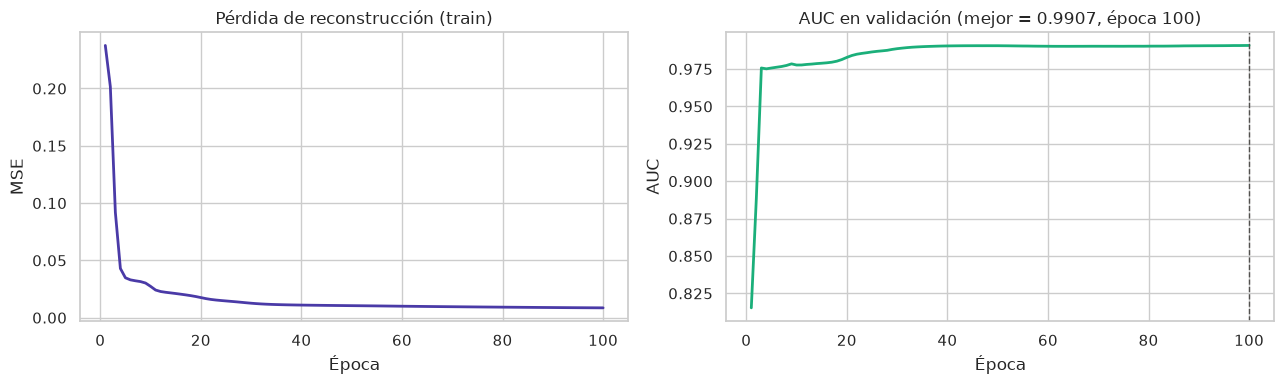

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, EPOCAS + 1), hist.history["loss"], color="#4a3aa7", linewidth=2)
axes[0].set(title="Pérdida de reconstrucción (train)", xlabel="Época", ylabel="MSE")
axes[1].plot(range(1, EPOCAS + 1), cb_auc.historial_auc, color="#1baf7a", linewidth=2)
axes[1].axvline(cb_auc.mejor_epoca, color="#52514e", linestyle="--", linewidth=1)
axes[1].set(title=f"AUC en validación (mejor = {cb_auc.mejor_auc:.4f}, época {cb_auc.mejor_epoca})",
            xlabel="Época", ylabel="AUC")
plt.tight_layout()
plt.show()

## Selección del umbral
Paso 4 del artículo:
1. La distancia de reconstrucción de validación se estandariza (z-score) con la **media y la desviación estándar de los normales de validación**.
2. Se barre el umbral de −4 a 4 en pasos de 0,01.
3. Se elige el umbral con **mayor MCC** en validación. El artículo dice solo que "mejor separa las clases"; se usa el MCC por ser su métrica principal.

En test (paso 5) se usan la **misma media, desviación estándar y umbral** de validación: nada se recalcula con datos de test.

In [30]:
UMBRALES = np.round(np.arange(-4, 4 + 1e-9, 0.01), 2)


def mcc_por_umbral(z, y, umbrales=UMBRALES):
    """MCC de 'z > umbral' para cada umbral, vectorizado."""
    y = np.asarray(y).astype(bool)
    pred = z[None, :] > umbrales[:, None]
    tp = (pred & y).sum(axis=1).astype(float)
    fp = (pred & ~y).sum(axis=1).astype(float)
    fn = y.sum() - tp
    tn = (~y).sum() - fp
    denom = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.divide(tp * tn - fp * fn, denom, out=np.zeros_like(tp), where=denom > 0)


def elegir_umbral(error_val, y_val):
    """Devuelve (umbral, media, std) usando solo los normales de validación para estandarizar."""
    normales = error_val[np.asarray(y_val) == 0]
    media, std = normales.mean(), normales.std()
    mccs = mcc_por_umbral((error_val - media) / std, y_val)
    return UMBRALES[np.argmax(mccs)], media, std

## Experimento
Cada corrida (estructura, latente, semilla) entrena, selecciona la mejor época por AUC, elige el umbral en validación y evalúa en test. Además de las métricas globales se guarda la TPR por categoría de ataque y la TPR en ataques que solo aparecen en test, comparables con el *baseline* XGBoost.

Cada corrida se agrega al CSV en cuanto termina; si el proceso se interrumpe, al relanzarlo se saltan las corridas ya guardadas.

In [31]:
SEMILLAS = [SEED + i for i in range(10)]
CORRIDAS_CSV = RESULTADOS_DIR / "ae_nslkdd_corridas.csv"

# Fase 1: tres estructuras con el mejor z del artículo. Fase 2: barrido de z en (5, 64)
CONFIGURACIONES = [(p, a, z) for (p, a), z in MEJOR_Z_PAPER.items()]
CONFIGURACIONES += [(5, 64, z) for z in LATENTES_BARRIDO if (5, 64, z) not in CONFIGURACIONES]


def correr_configuracion(profundidad, ancho, tam_latente, semilla, epocas=EPOCAS):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    modelo = construir_autoencoder(N_ENTRADA, profundidad, ancho, tam_latente)
    cb_auc = MejorAUC(X_val_ae, y_val)
    inicio = time.perf_counter()
    modelo.fit(X_train_ae, X_train_ae, epochs=epocas, batch_size=BATCH,
               shuffle=True, callbacks=[cb_auc], verbose=0)

    umbral, media, std = elegir_umbral(error_reconstruccion(modelo, X_val_ae), y_val)
    z_test = (error_reconstruccion(modelo, X_test_ae) - media) / std
    pred = (z_test > umbral).astype(int)

    fila = {"estructura": f"({profundidad},{ancho})", "profundidad": profundidad, "ancho": ancho,
            "latente": tam_latente, "semilla": semilla, "n_params": modelo.count_params(),
            "mejor_epoca": cb_auc.mejor_epoca, "auc_val": cb_auc.mejor_auc, "umbral": umbral,
            **calcular_metricas(y_test, pred, z_test)}
    # TPR por categoría y en ataques nuevos (FPR ya está en las métricas globales)
    for cat in CATEGORY_ORDER:
        fila[f"tpr_{cat}"] = pred[(detalle_test["categoria"] == cat).to_numpy()].mean()
    ataques_nuevos = ((detalle_test["attack"] == 1) & ~detalle_test["visto_en_train"]).to_numpy()
    fila["tpr_solo_test"] = pred[ataques_nuevos].mean()
    fila["segundos"] = time.perf_counter() - inicio
    return fila


def correr_experimento(configuraciones, semillas, ruta_csv, epocas=EPOCAS):
    hechas = set()
    if ruta_csv.exists():
        previas = pd.read_csv(ruta_csv)
        hechas = set(zip(previas["profundidad"], previas["ancho"], previas["latente"], previas["semilla"]))
    pendientes = [(p, a, z, s) for p, a, z in configuraciones for s in semillas if (p, a, z, s) not in hechas]
    print(f"Corridas: {len(pendientes)} pendientes de {len(configuraciones) * len(semillas)}")

    for i, (p, a, z, s) in enumerate(pendientes, start=1):
        fila = correr_configuracion(p, a, z, s, epocas)
        pd.DataFrame([fila]).to_csv(ruta_csv, mode="a", header=not ruta_csv.exists(), index=False)
        print(f"[{i}/{len(pendientes)}] ({p},{a}) z={z} semilla={s} | MCC = {fila['mcc']:.3f} | "
              f"{fila['segundos']:.0f} s", flush=True)


print(f"{len(CONFIGURACIONES)} configuraciones × {len(SEMILLAS)} semillas = "
      f"{len(CONFIGURACIONES) * len(SEMILLAS)} corridas")
CONFIGURACIONES

12 configuraciones × 10 semillas = 120 corridas


[(5, 32, 4),
 (5, 64, 3),
 (7, 64, 9),
 (5, 64, 1),
 (5, 64, 2),
 (5, 64, 4),
 (5, 64, 6),
 (5, 64, 8),
 (5, 64, 12),
 (5, 64, 16),
 (5, 64, 24),
 (5, 64, 31)]

In [32]:
# Cambiar a True para lanzar el experimento (~1,4 h en GPU). Se puede relanzar: retoma donde quedó
LANZAR_EXPERIMENTO = True

if LANZAR_EXPERIMENTO:
    correr_experimento(CONFIGURACIONES, SEMILLAS, CORRIDAS_CSV)

Corridas: 0 pendientes de 120


## Resultados del autoencoder
Promedio y desviación estándar sobre las semillas, por configuración (como en la Tabla 5 del artículo).

In [33]:
METRICAS = ["umbral", "accuracy", "tpr", "fpr", "mcc", "f1", "auc"]

if CORRIDAS_CSV.exists():
    corridas = pd.read_csv(CORRIDAS_CSV)
    resumen_ae = (corridas.groupby(["estructura", "latente"])[METRICAS]
                  .agg(["mean", "std"]).round(3))
    resumen_ae.insert(0, "n_semillas", corridas.groupby(["estructura", "latente"]).size())
    display(resumen_ae)
else:
    print("Aún no hay resultados: lanzar el experimento.")

n_semillas umbral        accuracy           tpr         \
                                mean    std     mean    std   mean    std   
estructura latente                                                          
(5,32)     4               10  2.482  0.173    0.822  0.019  0.716  0.030   
(5,64)     1               10  2.353  0.191    0.809  0.007  0.685  0.007   
           2               10  2.656  0.204    0.809  0.011  0.700  0.025   
           3               10  2.564  0.185    0.818  0.017  0.709  0.030   
           4               10  2.681  0.233    0.820  0.028  0.712  0.047   
           6               10  2.778  0.191    0.825  0.023  0.713  0.043   
           8               10  2.747  0.303    0.815  0.012  0.697  0.023   
           12              10  2.839  0.274    0.820  0.016  0.708  0.030   
           16              10  2.824  0.390    0.812  0.014  0.695  0.031   
           24              10  2.510  0.335    0.814  0.010  0.697  0.022   
           31              10  2.692  0.133    0.813  0.018  0.693  0.036   
(7,64)     9               10  2.751  0.358    0.813  0.012  0.705  0.023   

                      fpr           mcc            f1           auc         
                     mean    std   mean    std   mean    std   mean    std  
estructura latente                                                          
(5,32)     4        0.038  0.015  0.679  0.032  0.820  0.021  0.956  0.005  
(5,64)     1        0.027  0.016  0.664  0.017  0.803  0.007  0.957  0.003  
           2        0.047  0.026  0.656  0.022  0.806  0.013  0.956  0.002  
           3        0.039  0.022  0.673  0.030  0.816  0.020  0.954  0.010  
           4        0.037  0.021  0.677  0.048  0.818  0.032  0.956  0.006  
           6        0.028  0.005  0.688  0.035  0.822  0.027  0.957  0.004  
           8        0.028  0.005  0.674  0.016  0.811  0.015  0.955  0.008  
           12       0.031  0.004  0.680  0.023  0.817  0.019  0.955  0.003  
           16       0.033  0.015  0.667  0.020  0.808  0.019  0.953  0.004  
           24       0.031  0.005  0.671  0.014  0.810  0.013  0.955  0.004  
           31       0.029  0.006  0.670  0.026  0.808  0.023  0.954  0.003  
(7,64)     9        0.043  0.025  0.665  0.023  0.811  0.013  0.956  0.006

# Alternativa lineal: PCA como detector de anomalías
Un autoencoder **lineal** entrenado con MSE aprende el mismo subespacio que PCA. Por eso un PCA ajustado solo con tráfico normal equivale al autoencoder sin no linealidad, y sirve para medir cuánto aportan ReLU y la profundidad.

Se usa exactamente el mismo protocolo que con el autoencoder:
1. Entrada: `X_train_ae` (solo normales del train, mismo preprocesamiento).
2. Score: distancia L2 entre cada registro y su reconstrucción desde las primeras *k* componentes. Un ataque que no se parece a lo normal queda lejos del subespacio y se reconstruye mal.
3. Umbral: z-score con los normales de validación y barrido por MCC (`elegir_umbral`).

PCA es determinista, así que no requiere semillas.

## ¿Cuántas componentes conservar?
Se mira la varianza explicada acumulada sobre los normales del train. Se evalúan los mismos valores de *k* que los tamaños de latente del barrido del autoencoder (para comparar uno a uno) más los *k* que explican el 80, 90, 95 y 99 % de la varianza.

80% de la varianza -> k = 7
90% de la varianza -> k = 13
95% de la varianza -> k = 19
99% de la varianza -> k = 35


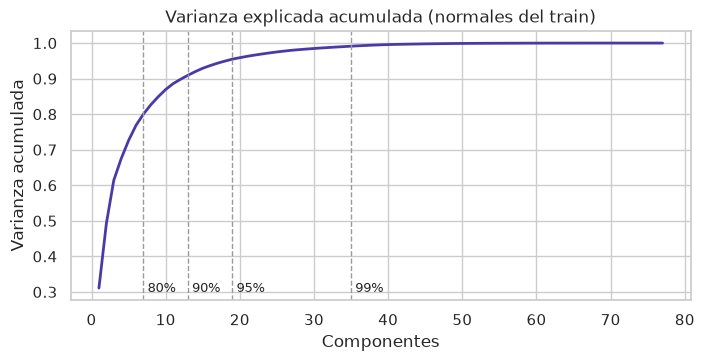

In [34]:
from sklearn.decomposition import PCA

pca_completo = PCA(svd_solver="full").fit(X_train_ae)
var_acum = np.cumsum(pca_completo.explained_variance_ratio_)
K_VARIANZA = {p: int(np.searchsorted(var_acum, p) + 1) for p in [0.80, 0.90, 0.95, 0.99]}
for p, k in K_VARIANZA.items():
    print(f"{p:.0%} de la varianza -> k = {k}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum, color="#4a3aa7", linewidth=2)
for p, k in K_VARIANZA.items():
    ax.axvline(k, color="#9a9a9a", linewidth=1, linestyle="--")
    ax.annotate(f"{p:.0%}", (k, 0.3), xytext=(3, 0), textcoords="offset points", fontsize=9)
ax.set(title="Varianza explicada acumulada (normales del train)", xlabel="Componentes", ylabel="Varianza acumulada")
plt.show()

In [35]:
def evaluar_pca(k):
    # PCA con k componentes ajustado con los normales del train, evaluado igual que el autoencoder
    pca = PCA(n_components=k, svd_solver="full").fit(X_train_ae)

    def error(X):
        return np.linalg.norm(X - pca.inverse_transform(pca.transform(X)), axis=1)

    error_val = error(X_val_ae)
    umbral, media, std = elegir_umbral(error_val, y_val)
    z_test = (error(X_test_ae) - media) / std
    pred = (z_test > umbral).astype(int)

    fila = {"k": k, "var_explicada": var_acum[k - 1], "auc_val": roc_auc_score(y_val, error_val),
            "umbral": umbral, **calcular_metricas(y_test, pred, z_test)}
    for cat in CATEGORY_ORDER:
        fila[f"tpr_{cat}"] = pred[(detalle_test["categoria"] == cat).to_numpy()].mean()
    ataques_nuevos = ((detalle_test["attack"] == 1) & ~detalle_test["visto_en_train"]).to_numpy()
    fila["tpr_solo_test"] = pred[ataques_nuevos].mean()
    return fila


K_PCA = sorted(set(LATENTES_BARRIDO) | set(K_VARIANZA.values()))
resultados_pca = pd.DataFrame([evaluar_pca(k) for k in K_PCA])
resultados_pca.to_csv(RESULTADOS_DIR / "pca_nslkdd.csv", index=False)

# k seleccionado como el autoencoder: mayor AUC en validación
K_ELEGIDO = int(resultados_pca.loc[resultados_pca["auc_val"].idxmax(), "k"])
print("k seleccionado por AUC de validación:", K_ELEGIDO)
resultados_pca.round(3)

k seleccionado por AUC de validación: 4


,k,var_explicada,auc_val,umbral,accuracy,tpr,fpr,f1,mcc,auc,tpr_DoS,tpr_Probe,tpr_R2L,tpr_U2R,tpr_solo_test
0,1,0.311,0.977,1.42,0.822,0.715,0.036,0.821,0.681,0.951,0.856,0.974,0.103,0.755,0.645
1,2,0.492,0.981,1.80,0.813,0.689,0.023,0.808,0.673,0.961,0.851,0.942,0.035,0.610,0.619
2,3,0.614,0.988,2.47,0.796,0.658,0.021,0.786,0.649,0.960,0.840,0.848,0.036,0.125,0.514
3,4,0.675,0.989,2.51,0.795,0.654,0.018,0.784,0.649,0.961,0.840,0.798,0.052,0.265,0.528
4,6,0.769,0.985,1.87,0.833,0.776,0.092,0.841,0.677,0.953,0.898,0.954,0.316,0.395,0.709
5,7,0.800,0.983,1.44,0.892,0.910,0.132,0.905,0.779,0.950,0.914,0.978,0.836,0.940,0.901
6,8,0.827,0.983,1.34,0.897,0.921,0.135,0.911,0.790,0.950,0.913,0.979,0.891,0.950,0.905
7,12,0.898,0.985,2.39,0.822,0.753,0.086,0.828,0.662,0.949,0.811,0.867,0.513,0.485,0.685
8,13,0.909,0.980,1.39,0.896,0.923,0.139,0.910,0.788,0.943,0.923,0.975,0.873,0.950,0.915
9,16,0.937,0.980,1.70,0.890,0.851,0.060,0.898,0.784,0.954,0.921,0.943,0.576,0.935,0.765


### PCA frente al autoencoder
Se compara el PCA seleccionado con el autoencoder seleccionado, (5,64) con z = 6 (promedio de 10 semillas), y con el XGBoost.

In [36]:
AE_ELEGIDO = ("(5,64)", 6)
COLS_COMPARAR = ["auc", "mcc", "tpr", "fpr", "tpr_DoS", "tpr_Probe", "tpr_R2L", "tpr_U2R", "tpr_solo_test"]

ae_sel = corridas[(corridas["estructura"] == AE_ELEGIDO[0]) & (corridas["latente"] == AE_ELEGIDO[1])]
comparacion = pd.DataFrame({
    f"PCA k={K_ELEGIDO}": resultados_pca.set_index("k").loc[K_ELEGIDO, COLS_COMPARAR],
    f"AE {AE_ELEGIDO[0]} z={AE_ELEGIDO[1]}": ae_sel[COLS_COMPARAR].mean(),
}).T
comparacion.round(3)

,auc,mcc,tpr,fpr,tpr_DoS,tpr_Probe,tpr_R2L,tpr_U2R,tpr_solo_test
PCA k=4,0.961,0.649,0.654,0.018,0.84,0.798,0.052,0.265,0.528
"AE (5,64) z=6",0.957,0.688,0.713,0.028,0.87,0.888,0.153,0.490,0.633


## Proyección de los ataques: submuestreo estratificado y UMAP
Para visualizar se toma una submuestra del test **estratificada por categoría** (Normal, DoS, Probe, R2L, U2R), de modo que conserve la proporción de cada tipo de ataque. Sobre ella:

1. **Espacio PCA:** se proyecta con el PCA de `K_ELEGIDO` componentes ajustado con los normales del train.
2. **Espacio latente:** se entrena una vez el autoencoder seleccionado, (5,64) con z = 6, se extrae la salida de la capa `latente` y se le aplica un PCA ajustado con los normales del train.
3. **UMAP** lleva cada espacio a 2D. UMAP no usa las etiquetas: solo sirven para colorear.

UMAP deforma las distancias. La figura muestra cómo se agrupan los datos, pero no mide si se pueden detectar: eso lo dicen las métricas de arriba.

In [37]:
import umap

N_MUESTRA = 6000
idx_muestra, _ = train_test_split(np.arange(len(detalle_test)), train_size=N_MUESTRA,
                                  stratify=detalle_test["categoria"], random_state=SEED)
categoria_muestra = detalle_test["categoria"].to_numpy()[idx_muestra]
print(pd.Series(categoria_muestra).value_counts())

# 1. Espacio PCA (ajustado con los normales del train)
pca_elegido = PCA(n_components=K_ELEGIDO, svd_solver="full").fit(X_train_ae)
proy_pca = pca_elegido.transform(X_test_ae[idx_muestra])

# 2. Espacio latente del autoencoder seleccionado (una corrida, semilla SEED)
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
ae_viz = construir_autoencoder(N_ENTRADA, 5, 64, AE_ELEGIDO[1])
ae_viz.fit(X_train_ae, X_train_ae, epochs=EPOCAS, batch_size=BATCH, shuffle=True,
           callbacks=[MejorAUC(X_val_ae, y_val)], verbose=0)
encoder = Model(ae_viz.input, ae_viz.get_layer("latente").output)
latente_train = encoder.predict(X_train_ae, batch_size=4096, verbose=0)
latente_muestra = encoder.predict(X_test_ae[idx_muestra], batch_size=4096, verbose=0)
print("Neuronas latentes activas (no siempre 0):", int((latente_train.max(axis=0) > 0).sum()), "de", AE_ELEGIDO[1])

pca_latente = PCA(svd_solver="full").fit(latente_train)
proy_latente = pca_latente.transform(latente_muestra)

# 3. UMAP a 2D de cada espacio
umap_pca = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(proy_pca)
umap_latente = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(proy_latente)

Normal    2585
DoS       1985
R2L        733
Probe      644
U2R         53
Name: count, dtype: int64


I0000 00:00:1792013442.367597 1229198 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50033__.9


I0000 00:00:1792013444.847695 1229195 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50033__.9


I0000 00:00:1792013469.409477 1229194 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Neuronas latentes activas (no siempre 0): 4 de 6


/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


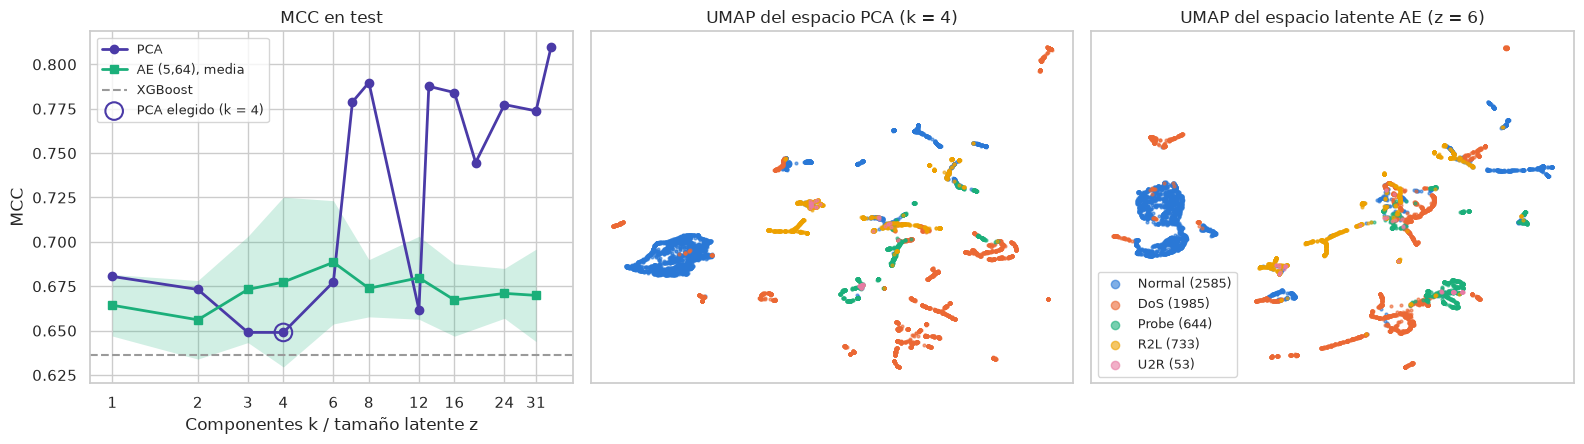

In [38]:
COLORES_VIZ = {"Normal": CLASS_PALETTE["Normal"], **CATEGORY_PALETTE}
ae_por_z = corridas[corridas["estructura"] == "(5,64)"].groupby("latente")["mcc"].agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# Desempeño: MCC en test según k (PCA) o z (autoencoder)
ax = axes[0]
ax.plot(resultados_pca["k"], resultados_pca["mcc"], marker="o", color="#4a3aa7", linewidth=2, label="PCA")
ax.plot(ae_por_z.index, ae_por_z["mean"], marker="s", color="#1baf7a", linewidth=2, label="AE (5,64), media")
ax.fill_between(ae_por_z.index, ae_por_z["mean"] - ae_por_z["std"], ae_por_z["mean"] + ae_por_z["std"],
                color="#1baf7a", alpha=0.2, linewidth=0)
ax.axhline(baseline_xgb.loc[baseline_xgb["conjunto"] == "test", "mcc"].item(), color="#9a9a9a",
           linestyle="--", linewidth=1.5, label="XGBoost")
ax.set_xscale("log", base=2)
ax.set_xticks(LATENTES_BARRIDO)
ax.set_xticklabels(LATENTES_BARRIDO)
ax.minorticks_off()
fila_k = resultados_pca.set_index("k").loc[K_ELEGIDO]
ax.scatter(K_ELEGIDO, fila_k["mcc"], s=160, facecolors="none", edgecolors="#4a3aa7", linewidths=1.5,
           label=f"PCA elegido (k = {K_ELEGIDO})", zorder=3)
ax.set(title="MCC en test", xlabel="Componentes k / tamaño latente z", ylabel="MCC")
ax.legend(fontsize=9)

# Proyecciones UMAP: normales primero, ataques encima
for ax, emb, titulo in [(axes[1], umap_pca, f"UMAP del espacio PCA (k = {K_ELEGIDO})"),
                        (axes[2], umap_latente, f"UMAP del espacio latente AE (z = {AE_ELEGIDO[1]})")]:
    for cat in ["Normal"] + CATEGORY_ORDER:
        m = categoria_muestra == cat
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=COLORES_VIZ[cat], label=f"{cat} ({m.sum()})")
    ax.set(title=titulo, xticks=[], yticks=[])
axes[2].legend(markerscale=3, fontsize=9, loc="best")

plt.tight_layout()
fig.savefig("figuras/pca_umap_nslkdd.png", dpi=200, bbox_inches="tight")
plt.show()

PCA genera un desempeño sorprendentemente alto. Si bien el autoencoer obitene el mejor MCC, la diferencia general es pequeña, por lo que se concluye que el componente no lineal aportado por el autoencoder puede no ser tan significativo. Sin embargo, el autoencoder justifica su implementacion al detectar los ataques dificiles:  detecta el 49 % de U2R contra el 27 % del PCA, y el 63 % de los ataques nuevos contra el 53 %.